# 41 — Metadados ambientais do IARA: vento, estado do mar e os erros de LARGE

**Pergunta.** Além do áudio, o IARA traz alguns metadados por gravação (chuva, vento, estado do mar, instante do CPA). Eles ajudam a entender os erros do experimento `mix_small_medium` (NB40)? Dá para aproveitá-los?

**Resumo das respostas:**
1. **Os metadados públicos são poucos:** chuva, vento e estado do mar (de uma estação próxima) e o instante do CPA. **Não há data, hora nem observatório**, e os dados brutos (áudio contínuo, AIS) só por solicitação ao projeto PMPAS-BS.
2. **Os LARGE foram gravados com o mar mais calmo** (mar ≤ 2 em 58% das gravações, contra 43–46% de SMALL e MEDIUM): um viés da base.
3. **A MLP mix_small_medium erra mais LARGE com o mar agitado:** com CPA, 81% → 69%; sem CPA, 54% → 45%.
4. **Misturar ruído real de mar agitado nos LARGE de treino não ajudou:** recall de LARGE 67,7% → 66,1% no split por navio, e os LARGE de mar agitado também não melhoraram. Nenhuma diferença foi significativa (menor p = 0,07).

## Glossário rápido

- **Estado do mar:** escala de 0 a 9 da agitação da superfície. No IARA, **estimado a partir do vento** de uma estação meteorológica próxima, não medido no hidrofone.
- **CPA (*Closest Point of Approach*):** instante em que o navio passa mais perto do hidrofone. Subconjuntos A (até 250 m) e C (250–500 m) contêm o CPA; B e D não.
- **Split por navio:** nenhum navio aparece no treino e no teste ao mesmo tempo (folds do NB29).
- **Augmentation:** criar versões modificadas das gravações de treino; aqui, misturar o áudio de um navio com uma gravação real de mar sem navio.
- **Valor-p (teste F 5x2cv):** abaixo de 0,05, a diferença entre dois métodos provavelmente é real.

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
warnings.filterwarnings('ignore')
try:
    from IPython.display import display
except ImportError:
    display = print
for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 120})
pd.set_option('display.precision', 1); pd.set_option('display.width', 200)

CN = {0: 'SMALL', 1: 'MEDIUM', 2: 'LARGE', 3: 'BACKGROUND'}
CM = {0: 'MIX_SMALL_MEDIUM', 1: 'LARGE', 2: 'BACKGROUND'}
MAPA = {0: 0, 1: 0, 2: 1, 3: 2}
meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'), dtype={'Ship ID': str, 'ID': str})
RAW_COLS = list(meta.columns)
meta = meta[meta.Dataset.isin(list('ABCDE'))].copy()
meta.index = meta.ID.astype(int); meta['Ship ID'] = meta['Ship ID'].str.strip()
meta['Length'] = pd.to_numeric(meta.Length, errors='coerce')
meta['Target'] = np.select([meta.Length < 50, meta.Length < 100, meta.Length >= 100], [0, 1, 2], default=3)
meta.loc[meta.Dataset == 'E', 'Target'] = 3
meta['Classe'] = meta.Target.map(CN)
meta['Vento'] = pd.to_numeric(meta.Wind, errors='coerce')
meta['Mar'] = pd.to_numeric(meta['Sea state'], errors='coerce')
meta['Chuva'] = pd.to_numeric(meta.Rain, errors='coerce')
meta['CPA'] = meta.Dataset.isin(['A', 'C'])
meta['Mar agitado'] = meta.Mar >= 3

## 1. Que metadados existem

O IARA é publicado no Zenodo (DOI 10.5281/zenodo.15777429, licença CC BY-NC 4.0) como áudios já recortados (A.zip a H.zip) e uma planilha `iara.xlsx`. A planilha foi copiada para `src/iara/dataset_info/iara.csv`.

In [2]:
cob = pd.DataFrame({'preenchido (%)': [100 * (meta[c].astype(str).str.strip() != '-').mean() for c in RAW_COLS]}, index=RAW_COLS)
cob['exemplo'] = [meta[c].astype(str).iloc[0] for c in RAW_COLS]
print('Colunas da planilha de metadados do IARA (subconjuntos A–E):'); display(cob)

Colunas da planilha de metadados do IARA (subconjuntos A–E):


,preenchido (%),exemplo
ID,100.0,0001
Dataset,100.0,A
Recording time,100.0,282
Rain,98.5,0
Rain state,98.5,No rain
Wind,98.1,2.7
Sea state,98.1,2
Name,84.7,MAERSK PACER
CPA time,46.7,150
Ship ID,84.7,323


**Leitura.**
- **Não há data nem hora da gravação** (a coluna `Recording time` é a **duração** em segundos), **nem o observatório** de origem. Os arquivos WAV também não trazem essa informação no cabeçalho.
- O que existe: chuva, vento e estado do mar (de uma estação próxima), o instante do CPA (só A e C) e os dados do navio (nome, tipo, comprimento; na planilha original também MMSI e IMO).
- **Os dados brutos não são públicos.** As gravações contínuas dos observatórios e o AIS pertencem ao projeto de monitoramento da Petrobras (PMPAS-BS). O portal do projeto (SIMMAO) mostra dados processados (mapas de ruído, espectros, densidade de tráfego) e tem um formulário de **solicitação de dados para fins científicos**. Sem data e observatório, não dá para testar efeitos de época ou de equipamento.

## 2. Os LARGE foram gravados com o mar mais calmo

In [3]:
CLIMA = meta.groupby('Classe').agg(gravações=('ID', 'size'), vento_mediana=('Vento', 'median'), mar_mediana=('Mar', 'median'),
                                   mar_calmo_pct=('Mar', lambda s: 100 * (s <= 2).mean()), chuva_pct=('Chuva', lambda s: 100 * (s > 0).mean()))
CLIMA = CLIMA.reindex(['SMALL', 'MEDIUM', 'LARGE', 'BACKGROUND'])
print('Condições de gravação por classe (por gravação):'); display(CLIMA)
MAR_DIST = pd.crosstab(meta.Classe, meta.Mar.fillna(-1).astype(int), normalize='index').mul(100).reindex(['SMALL', 'MEDIUM', 'LARGE', 'BACKGROUND'])
MAR_DIST = MAR_DIST.drop(columns=[-1], errors='ignore')
print('Estado do mar, % das gravações de cada classe:'); display(MAR_DIST.round(0))

# por navio: um ponto por navio
nav = meta[meta.Target < 3].groupby('Ship ID').agg(t=('Target', 'first'), vento=('Vento', 'mean'), mar=('Mar', 'mean'))
TESTE = []
for nome, a, b in [('LARGE × navios < 100 m', nav[nav.t < 2], nav[nav.t == 2]), ('MEDIUM × SMALL', nav[nav.t == 0], nav[nav.t == 1])]:
    for v in ['vento', 'mar']:
        x, y = a[v].dropna(), b[v].dropna(); u = st.mannwhitneyu(y, x)
        TESTE.append({'comparação': nome, 'variável': v, 'mediana 1º grupo': x.median(), 'mediana 2º grupo': y.median(),
                      'AUC (2º > 1º)': u.statistic / (len(x) * len(y)), 'p': u.pvalue, 'navios': f'{len(x)} × {len(y)}'})
TESTE = pd.DataFrame(TESTE)
print('Um ponto por navio (Mann-Whitney):'); display(TESTE.round(3))

Condições de gravação por classe (por gravação):


,gravações,vento_mediana,mar_mediana,mar_calmo_pct,chuva_pct
Classe,,,,,
SMALL,476,4.8,3.0,43.1,7.8
MEDIUM,397,4.7,3.0,45.8,4.8
LARGE,572,3.8,2.0,57.7,6.6
BACKGROUND,261,6.8,3.0,29.9,42.1


Estado do mar, % das gravações de cada classe:


Mar,1,2,3,4,5,6,7
Classe,,,,,,,
SMALL,11.0,32.0,30.0,16.0,5.0,3.0,0.0
MEDIUM,13.0,33.0,30.0,12.0,7.0,3.0,0.0
LARGE,25.0,33.0,22.0,12.0,3.0,2.0,0.0
BACKGROUND,11.0,19.0,21.0,21.0,14.0,14.0,0.0


Um ponto por navio (Mann-Whitney):


,comparação,variável,mediana 1º grupo,mediana 2º grupo,AUC (2º > 1º),p,navios
0,LARGE × navios < 100 m,vento,5.0,3.8,0.4,0.0,166 × 405
1,LARGE × navios < 100 m,mar,2.9,2.0,0.4,0.0,166 × 405
2,MEDIUM × SMALL,vento,4.7,5.0,0.5,0.6,85 × 81
3,MEDIUM × SMALL,mar,2.8,3.0,0.5,0.7,85 × 81


**Leitura.**
- **LARGE:** vento mediano 3,8 m/s e mar calmo (estado ≤ 2) em 58% das gravações. **SMALL e MEDIUM:** 4,8 e 4,7 m/s, mar calmo em 43% e 46%.
- **Por navio, a diferença é significativa** entre LARGE e os navios < 100 m (p < 0,001 para o estado do mar), mas **não entre SMALL e MEDIUM** (p = 0,714).
- **Chuva quase não aparece nas gravações de navio** (7–8%), mas aparece em 42% das de BACKGROUND, que foram escolhidas de propósito em condições variadas. Risco pequeno de o modelo associar "chuva" a "mar sem navio".
- **É um viés da base:** se os LARGE tivessem sido gravados nas mesmas condições dos outros, a separação entre as classes provavelmente seria um pouco menor.

## 3. O BACKGROUND cobre mar agitado

In [4]:
bg = meta[meta.Target == 3]
BG = pd.crosstab(bg.Mar.fillna(-1).astype(int), bg['Rain state'].str.strip(), margins=True, margins_name='total')
BG = BG[[c for c in ['No rain', 'Light', 'Moderate', 'Heavy', 'Very Heavy', 'total'] if c in BG.columns]]
BG.index.name = 'estado do mar'
print(f'BACKGROUND: {len(bg)} gravações (subconjunto {bg.Dataset.unique()[0]}); vento de {bg.Vento.min():.1f} a {bg.Vento.max():.1f} m/s')
display(BG)
BG_AGIT = int(((bg.Mar >= 4) & (bg['Rain state'].str.strip() == 'No rain')).sum())
BG_CALM = int(((bg.Mar <= 2) & (bg['Rain state'].str.strip() == 'No rain')).sum())
print(f'Fundos sem chuva com mar >= 4 (usados no augmentation "agitado"): {BG_AGIT}; com mar <= 2 ("calmo"): {BG_CALM}')

BACKGROUND: 261 gravações (subconjunto E); vento de 1.3 a 20.0 m/s


Rain state,No rain,Light,Moderate,Heavy,Very Heavy,total
estado do mar,,,,,,
1,25,3,0,0,0,28
2,25,16,7,2,0,50
3,25,19,8,2,1,55
4,25,20,5,4,0,54
5,25,7,4,0,0,36
6,25,5,4,1,2,37
7,1,0,0,0,0,1
total,151,70,28,9,3,261


Fundos sem chuva com mar >= 4 (usados no augmentation "agitado"): 76; com mar <= 2 ("calmo"): 50


**Leitura.** A seleção do BACKGROUND foi balanceada: **25 gravações sem chuva em cada estado do mar de 1 a 6**, mais as com chuva. Há 76 fundos sem chuva com mar ≥ 4 e 50 com mar ≤ 2: material suficiente para "sujar" gravações de navio com ruído de mar agitado (seção 5).

## 4. A MLP mix_small_medium erra mais LARGE com o mar agitado

Previsões da MLP do NB40 (split por navio), cruzadas com o estado do mar e a presença de CPA. A coluna `banda_31_86` é a energia mediana em 31–86 Hz (dB acima do fundo), a faixa grave que mais diferencia LARGE (NB40, seção 6).

In [5]:
ESP = pd.read_pickle(os.path.join(R.ROOT, 'data/iara_processed/cache_lofar_espectro_medio.pkl'))
F = (np.arange(1024) + 1) * 16000 / 2048
meta['banda_31_86'] = ESP.loc[:, (F >= 31) & (F < 86)].mean(1).reindex(meta.index)

def prev(exp):
    d = pd.concat([v.assign(fold=k) for k, v in R.file_predictions(exp).items()], ignore_index=True)
    d['File'] = d.File.astype(int)
    return d.join(meta[['Classe', 'Mar', 'Vento', 'CPA', 'Dataset', 'banda_31_86', 'Ship ID']], on='File')

def estratos(d, alvo):
    x = d[d.Target == alvo].copy()
    x['mar'] = np.where(x.Mar <= 2, 'calmo (0–2)', 'agitado (3+)')
    x['cpa'] = np.where(x.CPA, 'com CPA (A, C)', 'sem CPA (B, D)')
    g = x.assign(ok=x.Prediction == alvo).groupby(['cpa', 'mar']).agg(acerto=('ok', 'mean'), gravações=('File', 'nunique'),
                                                                        banda_31_86=('banda_31_86', 'median'))
    g['acerto'] *= 100
    return g.reindex(pd.MultiIndex.from_product([['com CPA (A, C)', 'sem CPA (B, D)'], ['calmo (0–2)', 'agitado (3+)']]))

BASE = prev('mix_small_medium_split_navio_mlp_lofar')
EST_L, EST_M = estratos(BASE, 1), estratos(BASE, 0)
print('MLP mix_small_medium, split por navio: acerto de LARGE por CPA × estado do mar'); display(EST_L.round(1))
print('Acerto de MIX_SMALL_MEDIUM por CPA × estado do mar'); display(EST_M.round(1))
x = BASE[BASE.Target == 1]
MAR_FINO = x.assign(ok=x.Prediction == 1).groupby(x.Mar.clip(upper=5)).ok.agg(['mean', 'size']).rename(columns={'mean': 'acerto LARGE', 'size': 'avaliações'})
MAR_FINO['acerto LARGE'] *= 100; MAR_FINO.index = [f'{int(i)}' if i < 5 else '5+' for i in MAR_FINO.index]
print('Acerto de LARGE por estado do mar (todas as gravações):'); display(MAR_FINO.round(1))

MLP mix_small_medium, split por navio: acerto de LARGE por CPA × estado do mar


acerto  gravações  banda_31_86
com CPA (A, C) calmo (0–2)     81.2        229          8.0
               agitado (3+)    68.6        156          7.1
sem CPA (B, D) calmo (0–2)     54.5        101          7.0
               agitado (3+)    44.7         86          5.8

Acerto de MIX_SMALL_MEDIUM por CPA × estado do mar


acerto  gravações  banda_31_86
com CPA (A, C) calmo (0–2)     76.9        194          5.3
               agitado (3+)    74.8        218          4.9
sem CPA (B, D) calmo (0–2)     80.7        193          4.6
               agitado (3+)    73.7        268          4.9

Acerto de LARGE por estado do mar (todas as gravações):


,acerto LARGE,avaliações
1,81.0,720
2,66.9,930
3,58.2,620
4,58.3,355
5+,61.4,145


**Leitura.**
- **O mar agitado tira cerca de 10 pontos do acerto de LARGE, com ou sem CPA:** com CPA, 81% (calmo) → 69% (agitado); sem CPA, 54% → **45%**.
- **A faixa grave fica mais fraca com o mar agitado** (8,0 → 7,1 dB com CPA): o ruído do mar sobe e o grave do navio se destaca menos do fundo.
- **Já a classe MIX_SMALL_MEDIUM quase não sofre** (77% → 75% com CPA), porque a pista dela não é o grave forte.
- Por estado do mar: LARGE acerta 81% com mar 1 e 58–58% com mar 3–4.

## 5. Augmentation: LARGE misturado com fundo de mar agitado

**Ideia:** mostrar ao modelo LARGE "sujos" por ruído real de mar agitado.

**Como foi feito** (`scripts/extrair_lofar_mixbg_mar.py` e `scratch/mix_small_medium/aug_mar.py`):
- Para cada gravação LARGE, o **áudio** é somado a uma gravação de BACKGROUND sem chuva com mar ≥ 4, com razão sinal/fundo sorteada entre 0 e 20 dB, e o LOFAR é recalculado igual ao do pipeline. O LOFAR original não é alterado.
- No treino de cada fold, cada gravação LARGE ganha **uma** versão misturada, usando só fundos que estão no **treino** daquele fold (sem vazamento). O teste é sempre o LOFAR original.
- Mesma MLP h32-16 e mesmos folds do NB40, nos dois splits.
- **Dois controles:** `dupL` (cópia idêntica do LARGE: mais exemplos LARGE, sem ruído) e `calmo` (mesma mistura, mas com fundo de mar calmo, ≤ 2). Assim dá para separar o efeito do mar agitado do efeito de só ter mais LARGE ou de qualquer fundo.

Médias de 10 folds:


SP   ACC  R_MIX_SMALL_MEDIUM  R_LARGE  R_BACKGROUND
split_navio sem augmentation                       74.5  74.6                76.2     67.7          79.9
            LARGE duplicado (controle)             75.2  75.4                78.2     67.1          81.0
            LARGE + fundo de mar calmo (controle)  74.6  74.9                79.3     64.4          80.8
            LARGE + fundo de mar agitado           74.1  74.3                78.0     66.1          78.8
split_id    sem augmentation                       78.0  78.1                82.4     70.6          81.5
            LARGE duplicado (controle)             78.1  78.3                84.2     69.6          81.2
            LARGE + fundo de mar calmo (controle)  77.2  77.5                86.5     64.3          81.8
            LARGE + fundo de mar agitado           77.0  77.2                82.9     68.0          80.6

Diferenças (F 5x2cv):


,split,variante,contra,métrica,Δ,folds melhores,p (F 5x2cv)
0,split_navio,dupL,base,ACC,0.8,8,1.3e-01
1,split_navio,dupL,base,R_LARGE,-0.6,4,7.9e-01
2,split_navio,dupL,base,R_MIX_SMALL_MEDIUM,1.9,8,6.3e-01
3,split_navio,calmo,base,ACC,0.3,5,4.6e-01
4,split_navio,calmo,base,R_LARGE,-3.2,2,1.9e-01
5,split_navio,calmo,base,R_MIX_SMALL_MEDIUM,3.1,7,7.0e-02
6,split_navio,calmo,dupL,ACC,-0.5,4,5.3e-01
7,split_navio,calmo,dupL,R_LARGE,-2.6,2,6.2e-01
8,split_navio,calmo,dupL,R_MIX_SMALL_MEDIUM,1.2,6,7.6e-01
9,split_navio,agitado,base,ACC,-0.3,3,6.8e-01


Acerto de LARGE (%) por CPA × estado do mar, split por navio:


sem augmentation  LARGE duplicado (controle)  LARGE + fundo de mar calmo (controle)  LARGE + fundo de mar agitado
com CPA (A, C) calmo (0–2)               81.2                        80.5                                   77.0                          78.3
               agitado (3+)              68.6                        67.9                                   67.1                          68.1
sem CPA (B, D) calmo (0–2)               54.5                        54.7                                   52.7                          54.9
               agitado (3+)              44.7                        43.0                                   39.1                          42.3

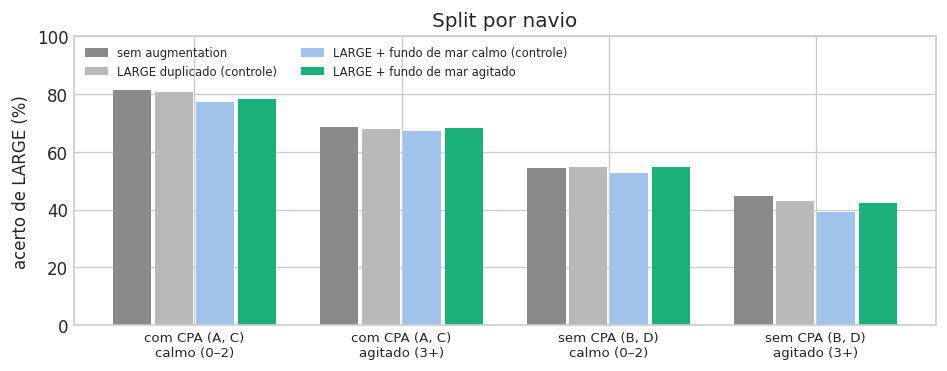

In [6]:
VAR = {'base': 'sem augmentation', 'dupL': 'LARGE duplicado (controle)', 'calmo': 'LARGE + fundo de mar calmo (controle)',
       'agitado': 'LARGE + fundo de mar agitado'}
def exp(cond, v):
    return f'mix_small_medium_{cond}_mlp_lofar' + ('' if v == 'base' else f'_aug{v}')
def metricas(y, p):
    rec = np.array([np.mean(p[y == c] == c) for c in range(3)])
    sp = np.sqrt(rec.mean() * np.exp(np.mean(np.log(rec)))) * 100 if np.all(rec > 0) else 0.0
    return {'SP': sp, 'ACC': rec.mean() * 100, **{f'R_{CM[c]}': r * 100 for c, r in enumerate(rec)}}
FMA, PREVA = {}, {}
for cond in ['split_navio', 'split_id']:
    for v in VAR:
        P = R.file_predictions(exp(cond, v))
        FMA[(cond, v)] = pd.DataFrame({k: metricas(d.Target.values, d.Prediction.values) for k, d in P.items()}).T
        if cond == 'split_navio': PREVA[v] = prev(exp(cond, v))
MEDIAS = pd.concat({(c, VAR[v]): f.mean() for (c, v), f in FMA.items()}, axis=1).T
print('Médias de 10 folds:'); display(MEDIAS.round(1))
rows = []
for cond in ['split_navio', 'split_id']:
    for v in ['dupL', 'calmo', 'agitado']:
        for ref in ['base', 'dupL']:
            if ref == v: continue
            A, B = FMA[(cond, v)], FMA[(cond, ref)]
            for m in ['ACC', 'R_LARGE', 'R_MIX_SMALL_MEDIUM']:
                rows.append({'split': cond, 'variante': v, 'contra': ref, 'métrica': m, 'Δ': (A[m] - B[m]).mean(),
                             'folds melhores': int((A[m] > B[m]).sum()), 'p (F 5x2cv)': R.f_test_5x2(A[m].values, B[m].values)[1]})
DELTA = pd.DataFrame(rows)
print('Diferenças (F 5x2cv):'); display(DELTA.round(3))
EST_AUG = pd.concat({VAR[v]: estratos(PREVA[v], 1).acerto for v in VAR}, axis=1)
print('Acerto de LARGE (%) por CPA × estado do mar, split por navio:'); display(EST_AUG.round(1))

fig, ax = plt.subplots(figsize=(8, 3.2))
lab = [f'{a}\n{b}' for a, b in EST_AUG.index]; xx = np.arange(len(lab)); w = 0.2
cores = {'sem augmentation': '#8a8a8a', 'LARGE duplicado (controle)': '#b9b9b9', 'LARGE + fundo de mar calmo (controle)': '#9fc3ea',
         'LARGE + fundo de mar agitado': '#1baf7a'}
for i, c in enumerate(EST_AUG.columns):
    ax.bar(xx + (i - 1.5) * w, EST_AUG[c].values, w * 0.92, color=cores[c], label=c)
ax.set_xticks(xx); ax.set_xticklabels(lab, fontsize=8); ax.set_ylabel('acerto de LARGE (%)'); ax.set_ylim(0, 100)
ax.legend(fontsize=7, ncol=2, loc='upper left'); ax.set_title('Split por navio')
plt.tight_layout(); plt.show()

**Leitura.**
- **Nenhuma variante melhora o modelo.** No split por navio, ACC: sem augmentation 74,6; LARGE duplicado 75,4; fundo calmo 74,9; **fundo agitado 74,3**. Todas as diferenças têm p > 0,05.
- **O recall de LARGE até cai um pouco quando se mistura fundo** (agitado -1,6, calmo -3,2 pontos; não significativo), enquanto o de MIX_SMALL_MEDIUM sobe um pouco. Como o fundo calmo faz o mesmo, **não é um efeito do mar agitado**: é o efeito de mostrar LARGE com o grave "diluído".
- **Os LARGE de mar agitado não melhoraram** (com CPA: 69% sem augmentation → 68% com fundo agitado; sem CPA: 45% → 42%).
- **Interpretação provável (não testada):** somar ruído ao LARGE de treino apaga parte do grave que o diferencia; o exemplo aumentado fica parecido com um navio < 100 m, e a fronteira fica mais confusa em vez de mais robusta. É a mesma limitação do NB40: quando o grave some do LOFAR, a informação não está lá para ser aprendida.

## 6. Dá para usar esses metadados direto no modelo?

Hoje os modelos recebem só o LOFAR. Pôr vento e estado do mar como entradas extras é fácil, mas **arriscado**: como os LARGE foram gravados com mar mais calmo, o modelo tenderia a aprender o atalho "mar calmo → LARGE", que melhora o número no IARA e piora no mundo real. Usos mais seguros:

1. **Augmentation direcionado** (seção 5): usa o metadado só para escolher o ruído, não como entrada.
2. **Abstenção:** com mar agitado e grave fraco, responder "inconclusivo" em vez de chutar.
3. **Medir o ruído pelo próprio áudio** (nível antes da normalização), em vez de usar a estação meteorológica.
4. **Reportar o desempenho por condição** (mar calmo × agitado, com × sem CPA).

## 7. Conclusões

1. **Os metadados ajudam a entender os erros, não a corrigi-los.** O mar agitado e a falta de CPA explicam boa parte dos erros de LARGE (45% de acerto quando as duas coisas se juntam).
2. **Há um viés de condição na base:** os LARGE foram gravados com o mar mais calmo. Os resultados do IARA para LARGE são, provavelmente, um pouco otimistas para condições reais.
3. **O augmentation com mar agitado não melhorou o modelo**, e o controle com mar calmo mostra que misturar qualquer fundo tende a tirar um pouco de recall de LARGE.
4. **Não recomendo usar vento e estado do mar como entrada do modelo** (risco de atalho "mar calmo → LARGE"). Usos mais úteis: reportar o desempenho por condição e permitir abstenção.
5. **O que mais ajudaria vem de fora do IARA público:** data, hora e observatório de cada gravação (para testar efeitos de época e equipamento) e mais navios distintos abaixo de 100 m. Ambos exigem solicitação aos autores ou ao PMPAS-BS (SIMMAO).